In [135]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [96]:
df= pd.read_csv("House_Rent_Dataset.csv")
df.head(15)

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,5/18/2022,2,10000.0,1100.0,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
1,5/13/2022,2,20000.0,NaN,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
2,5/16/2022,2,17000.0,1000.0,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
3,7/4/2022,2,10000.0,NaN,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner
4,5/9/2022,2,7500.0,850.0,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner
5,4/29/2022,2,7000.0,600.0,Ground out of 1,Super Area,Thakurpukur,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
6,6/21/2022,2,10000.0,700.0,Ground out of 4,Super Area,Malancha,Kolkata,Unfurnished,Bachelors,2.0,Contact Agent
7,6/21/2022,1,5000.0,250.0,1 out of 2,Super Area,Malancha,Kolkata,Unfurnished,Bachelors,1.0,Contact Agent
8,6/7/2022,2,26000.0,NaN,1 out of 2,Carpet Area,"Palm Avenue Kolkata, Ballygunge",Kolkata,Unfurnished,Bachelors,NaN,Contact Agent
9,6/20/2022,2,10000.0,1000.0,1 out of 3,Carpet Area,Natunhat,Kolkata,Semi-Furnished,Bachelors/Family,2.0,Contact Owner


In [97]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Posted On          4746 non-null   object 
 1   BHK                4746 non-null   int64  
 2   Rent               4741 non-null   float64
 3   Size               4738 non-null   float64
 4   Floor              4746 non-null   object 
 5   Area Type          4739 non-null   object 
 6   Area Locality      4746 non-null   object 
 7   City               4746 non-null   object 
 8   Furnishing Status  4746 non-null   object 
 9   Tenant Preferred   4746 non-null   object 
 10  Bathroom           4742 non-null   float64
 11  Point of Contact   4746 non-null   object 
dtypes: float64(3), int64(1), object(8)
memory usage: 445.1+ KB


In [98]:
df.describe()

,BHK,Rent,Size,Bathroom
count,4746.000000,4.741000e+03,4738.000000,4742.000000
mean,2.083860,3.502340e+04,967.936049,1.965837
std,0.832256,7.814214e+04,634.562635,0.884904
min,1.000000,1.200000e+03,10.000000,1.000000
25%,2.000000,1.000000e+04,550.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000
max,6.000000,3.500000e+06,8000.000000,10.000000


In [99]:
df.isna().sum()

,0
Posted On,0
BHK,0
Rent,5
Size,8
Floor,0
Area Type,7
Area Locality,0
City,0
Furnishing Status,0
Tenant Preferred,0


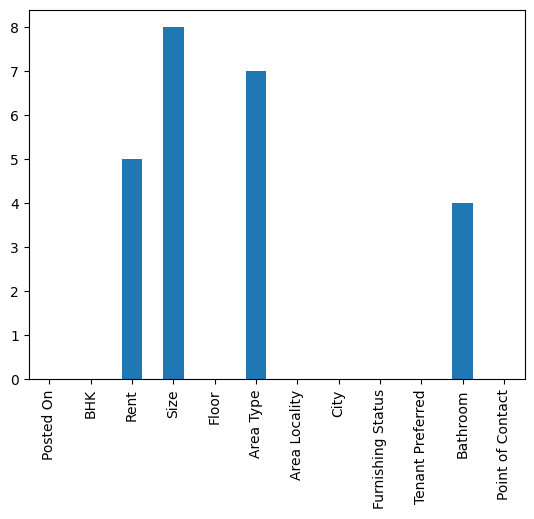

In [100]:
df.isna().sum().plot.bar()
plt.show()

In [101]:
df.shape

(4746, 12)

In [102]:
df.duplicated().sum()

np.int64(0)

In [103]:
df.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,5/18/2022,2,10000.0,1100.0,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
1,5/13/2022,2,20000.0,NaN,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
2,5/16/2022,2,17000.0,1000.0,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
3,7/4/2022,2,10000.0,NaN,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner
4,5/9/2022,2,7500.0,850.0,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner


In [104]:
df.drop("Posted On", inplace=True , axis = 1)

In [105]:
obj = [col for col in df.select_dtypes("object").columns]
obj

['Floor',
 'Area Type',
 'Area Locality',
 'City',
 'Furnishing Status',
 'Tenant Preferred',
 'Point of Contact']

In [106]:
from sklearn.impute import SimpleImputer
imput_frq = SimpleImputer(missing_values=np.nan, strategy='most_frequent')


In [107]:
for i in obj :
  if df[i].isna().sum() == 0 :
    continue
  else :
    df[i] = imput_frq.fit_transform(df[[i]]).ravel()

In [108]:
df.isna().sum()

,0
BHK,0
Rent,5
Size,8
Floor,0
Area Type,0
Area Locality,0
City,0
Furnishing Status,0
Tenant Preferred,0
Bathroom,4


In [109]:
numeric = [col for col in df.select_dtypes(["float" , int]).columns]
numeric

['BHK', 'Rent', 'Size', 'Bathroom']

BHK (Skew: 0.5992157733648072)
Rent (Skew: 21.402053848072253)
Size (Skew: 2.2981542396330705)
Bathroom (Skew: 1.2725152257787251)



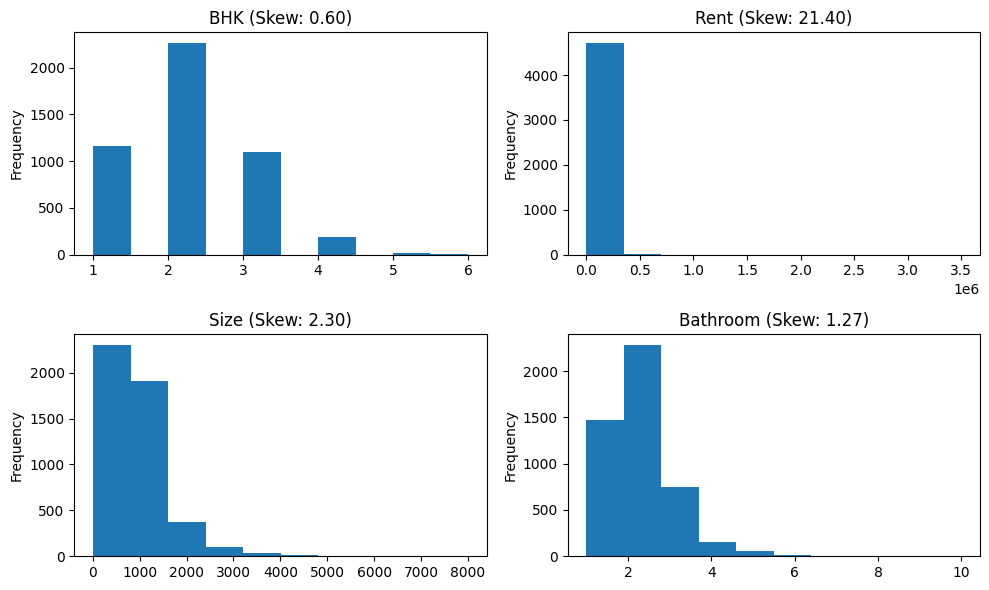

In [110]:
numeric = [col for col in df.select_dtypes(include=np.number).columns]

plt.figure(figsize=(10, 6))
for j, col in enumerate(numeric):
    plt.subplot(2, 2, j + 1)
    df[col].plot(kind ="hist")
    plt.title(f"{col} (Skew: {df[col].skew():.2f})")
    print(f"{col} (Skew: {df[col].skew()})")
print()
plt.tight_layout()
plt.show()

In [111]:
imput_mean = SimpleImputer(missing_values=np.nan, strategy='mean')
imput_median = SimpleImputer(missing_values=np.nan, strategy='median')


In [112]:
for j in numeric :
  if df[j].isna().sum() == 0 :
    continue
  else :
    if df[j].skew() > .5 :
      df[j] = imput_median.fit_transform(df[[j]])
    else :
      df[j] = imput_mean.fit_transform(df[[j]]).ravel()

In [113]:
df.isna().sum()

,0
BHK,0
Rent,0
Size,0
Floor,0
Area Type,0
Area Locality,0
City,0
Furnishing Status,0
Tenant Preferred,0
Bathroom,0


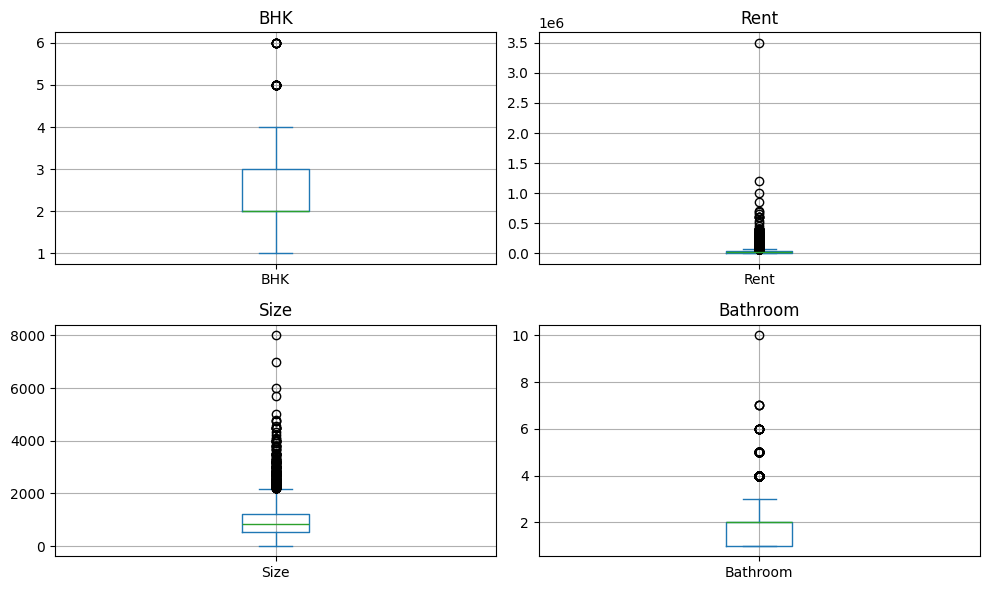

In [114]:
# Detect Outliers
plt.figure(figsize=(10, 6))
for j, col in enumerate(numeric):
    plt.subplot(2, 2, j + 1)
    df[col].plot(kind ="box")
    plt.title(f"{col}")
    plt.grid()
plt.tight_layout()
plt.show()

In [115]:
df.shape

(4746, 11)

In [116]:
def detect_remove_outliers(data, cols):
    cleaned_data = data.copy()
    for col in cols:
        Q1 = cleaned_data[col].quantile(0.25)
        Q3 = cleaned_data[col].quantile(0.75)
        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        cleaned_data = cleaned_data[(cleaned_data[col] >= lower) & (cleaned_data[col] <= upper)]
    return cleaned_data
print("Original shape:", df.shape)
cleaned_df = detect_remove_outliers(df, numeric)
df = cleaned_df
print("Cleaned shape:", cleaned_df.shape)

Original shape: (4746, 11)
Cleaned shape: (4078, 11)


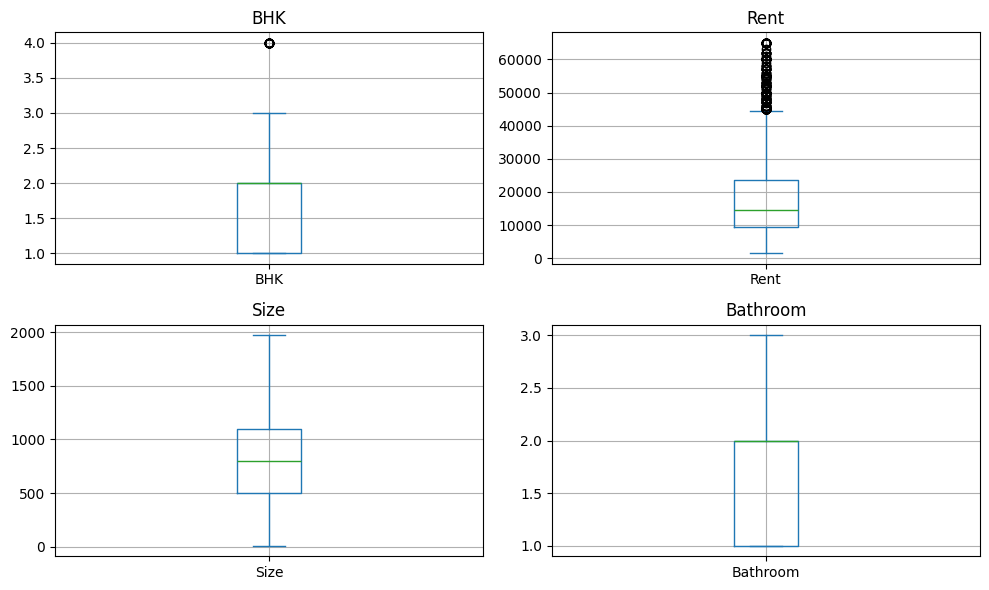

In [117]:
# Detect Outliers
plt.figure(figsize=(10, 6))
for j, col in enumerate(numeric):
    plt.subplot(2, 2, j + 1)
    df[col].plot(kind ="box")
    plt.title(f"{col}")
    plt.grid()
plt.tight_layout()
plt.show()

In [118]:
df.describe()

,BHK,Rent,Size,Bathroom
count,4078.000000,4078.000000,4078.000000,4078.000000
mean,1.911967,18591.399215,824.740069,1.754046
std,0.694312,13206.411140,408.488023,0.641984
min,1.000000,1500.000000,10.000000,1.000000
25%,1.000000,9325.000000,500.000000,1.000000
50%,2.000000,14500.000000,800.000000,2.000000
75%,2.000000,23500.000000,1100.000000,2.000000
max,4.000000,65000.000000,1970.000000,3.000000


In [121]:
obj = [col for col in df.select_dtypes("object").columns]

for col in obj:
  print(f"Number of Unique Values in {col}: {len(df[col].unique())}")
  print()
  print(f"Unique Values: {df[col].unique()}")
  print("*" * 50)

Number of Unique Values in Floor: 330

Unique Values: ['Ground out of 2' '1 out of 3' '1 out of 2' 'Ground out of 1'
 'Ground out of 4' '1 out of 4' '1 out of 1' '2 out of 3'
 'Ground out of 3' '4 out of 5' '2 out of 2' '2 out of 5' '4 out of 14'
 '3 out of 3' '5 out of 5' '4 out of 4' '7 out of 8' '2 out of 4'
 '3 out of 4' '1 out of 5' '8 out of 5' 'Ground out of 6' '2 out of 1'
 'Upper Basement out of 4' 'Ground out of 5' '3 out of 5' '11 out of 19'
 '5 out of 10' '11 out of 14' 'Lower Basement out of 2' '2 out of 7'
 '7 out of 10' '6 out of 7' '4 out of 7' '2 out of 8' '5 out of 12'
 '11 out of 21' '14 out of 23' '9 out of 20' 'Upper Basement out of 9'
 '19 out of 24' '3 out of 21' '1 out of 22' '3 out of 7' '8 out of 8'
 '6 out of 12' 'Upper Basement out of 16' '34 out of 48' '5 out of 8'
 '5 out of 14' '14 out of 40' '9 out of 22' '12 out of 18' '26 out of 44'
 '1 out of 8' 'Ground out of 7' '13 out of 20' '16 out of 23'
 '10 out of 18' '10 out of 32' '12 out of 24' '3 out of 30'

In [120]:
df.head()

,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2,10000.0,1100.0,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
1,2,20000.0,850.0,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
2,2,17000.0,1000.0,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
3,2,10000.0,850.0,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner
4,2,7500.0,850.0,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner


In [122]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

encoded = encoder.fit_transform(df[["Area Type"]])

encoded_df = pd.DataFrame(
    encoded,
    columns=encoder.get_feature_names_out(),
    index=df.index
)

df = pd.concat(
    [df.drop(columns="Area Type"), encoded_df],
    axis=1
)

In [124]:
df.head()

,BHK,Rent,Size,Floor,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Area Type_Built Area,Area Type_Carpet Area,Area Type_Super Area
0,2,10000.0,1100.0,Ground out of 2,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner,0.0,0.0,1.0
1,2,20000.0,850.0,1 out of 3,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner,0.0,0.0,1.0
2,2,17000.0,1000.0,1 out of 3,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner,0.0,0.0,1.0
3,2,10000.0,850.0,1 out of 2,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner,0.0,0.0,1.0
4,2,7500.0,850.0,1 out of 2,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner,0.0,1.0,0.0


In [123]:
current_obj = [col for col in df.select_dtypes("object").columns]
current_obj

['Floor',
 'Area Locality',
 'City',
 'Furnishing Status',
 'Tenant Preferred',
 'Point of Contact']

In [130]:
from sklearn.preprocessing import LabelEncoder

LE = LabelEncoder()

for col in current_obj:
 df[col] = LE.fit_transform(df[[col]])



/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,

In [131]:
df.head()

,BHK,Rent,Size,Floor,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Area Type_Built Area,Area Type_Carpet Area,Area Type_Super Area
0,2,10000.0,1100.0,308,193,4,2,1,2.0,2,0.0,0.0,1.0
1,2,20000.0,850.0,14,1336,4,1,1,1.0,2,0.0,0.0,1.0
2,2,17000.0,1000.0,14,1538,4,1,1,1.0,2,0.0,0.0,1.0
3,2,10000.0,850.0,10,467,4,2,1,1.0,2,0.0,0.0,1.0
4,2,7500.0,850.0,10,1655,4,2,0,1.0,2,0.0,1.0,0.0


In [143]:
df.describe()

,BHK,Rent,Size,Floor,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Area Type_Built Area,Area Type_Carpet Area,Area Type_Super Area
count,4078.000000,4078.000000,4078.000000,4078.000000,4078.000000,4078.000000,4078.000000,4078.000000,4078.000000,4078.000000,4078.000000,4078.000000,4078.000000
mean,1.911967,18591.399215,824.740069,159.390142,961.643453,2.277832,1.293771,0.917116,1.754046,1.510790,0.000490,0.434282,0.565228
std,0.694312,13206.411140,408.488023,109.617540,552.440343,1.718775,0.670347,0.503114,0.641984,0.859669,0.022143,0.495723,0.495788
min,1.000000,1500.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,9325.000000,500.000000,16.000000,492.000000,1.000000,1.000000,1.000000,1.000000,2.000000,0.000000,0.000000,0.000000
50%,2.000000,14500.000000,800.000000,150.000000,969.000000,2.000000,1.000000,1.000000,2.000000,2.000000,0.000000,0.000000,1.000000
75%,2.000000,23500.000000,1100.000000,252.000000,1427.750000,4.000000,2.000000,1.000000,2.000000,2.000000,0.000000,1.000000,1.000000
max,4.000000,65000.000000,1970.000000,329.000000,1954.000000,5.000000,2.000000,2.000000,3.000000,2.000000,1.000000,1.000000,1.000000


In [180]:
X = df.drop("Rent" , axis = 1)
y = df["Rent"]

In [181]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [185]:
from sklearn.preprocessing import StandardScaler

In [186]:
scalar = StandardScaler()
X_train = scalar.fit_transform(X_train)
X_test = scalar.transform(X_test )

In [187]:
from sklearn.linear_model import LinearRegression

In [188]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [189]:
y_pred = model.predict(X_test)

In [191]:
from sklearn.metrics import mean_absolute_error , mean_squared_error , r2_score

In [194]:
print(f"MAE: {mean_absolute_error(y_test , y_pred)}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test , y_pred))}")
print(f"MSE: {mean_squared_error(y_test , y_pred)}")
print(f"R2 Score: {r2_score(y_test , y_pred)}")

MAE: 6842.699717806417
RMSE: 9149.932395601338
MSE: 83721262.84407485
R2 Score: 0.4872948775651489
